# Introduction

* Transformer architecture was predominantly used for NLP specific tasks
* ViT architecture is an approach that attains comparable results to state-of-the-art CNN networks while requiring fewer computational resources to train, when pre-trained on large datasets
* Multiple works tried combining CNN-like architectures with self-attention (Wang et al., 2018 and Carion et al., 2020 (DETR)) or replacing the convolutions entirely (Ramachandran et al., 2019, Wang et al., 2020a)
* Models which replaced CNNs entirely have not yet been scaled effectively on modern hardware accelerators due to the use of specialized attention patterns
* Therefore, in large-scale image recognition, classic ResNet-like architectures in 2020 were still state of the art - ViT changed that, and as of 2026 ViT is a state-of-the-art model family for huge scale vision models training

# Methodology Description

* Inspired by Transformer scaling successes in NLP, paper experiments with applying a standard Transformer directly to images, with the fewest possible modifications
* Image is split into patches which are shaped into a sequence of linear embeddings which go as an input to a Transformer
* Image patches are treated the same way as tokens (words) in an NLP application
* We train the model on image classification in supervised fashion

# Outcomes

* Trained on mid-sized datasets such as ImageNet without strong regularization, these models yield modest accuracies of a few percentage points below ResNets of comparable size. That's expected, since transformers lack some of the inductive biases inherent to CNNs, such as translation equivariance and locality, and therefore do not generalize well when trained on insufficient amounts of data
* Picture changes if the models are trained on larger datasets (14M-300M images). We find that large scale training trumps inductive bias. Vision Transformer (ViT) attains excellent results when pre-trained at sufficient scale and transferred to tasks with fewer datapoints
* When pre-trained on the public ImageNet-21k dataset or the in-house JFT-300M dataset, ViT approaches or beats SOTA on multiple image recognition benchmarks. In particular, the best model reaches the accuracy of 88.55% on ImageNet, 90.72% on ImageNet-ReaL, 94.55% on CIFAR-100, and 77.63% on the VTAB suite of 19 tasks.

# ViT

## Imports

In [1]:
import os
import json
import math
import time
import platform
from functools import partial

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from datasets import load_dataset
from torchvision import transforms

/Users/adriankazi/Desktop/ViT/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Params

In [2]:
# Model - small ViT for CIFAR-100 from scratch
img_size = 32
patch_size = 4
embed_dim = 256
seq_len = (img_size // patch_size) ** 2   # 64
n_heads = 8
n_blocks = 12
mlp_dim = 4 * embed_dim                    # 1024
n_classes = 100

# Training - paper recipe (Adam, warmup + cosine, grad clip)
batch_size = 256
epochs = 200
base_lr = 1e-3
weight_decay = 0.05
dropout = 0.1
warmup_steps = 2_000
grad_clip = 1.0
betas = (0.9, 0.999)

device = torch.device('cuda:0' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')

## Import data

We use **CIFAR-100** (Krizhevsky, 2009), one of the transfer benchmarks reported in the paper (Table 2):

* 60,000 RGB images of size $32 \times 32$: 50,000 for training and 10,000 for testing
* 100 fine-grained classes (`fine_label`), 600 images per class, grouped into 20 superclasses (`coarse_label`, not used here)
* Loaded from Hugging Face (`uoft-cs/cifar100`), each example holds a PIL image `img` and its labels

Preprocessing follows the official ViT code, where pixel values are scaled to $[-1, 1]$:

$$x' = \frac{x - 0.5}{0.5}, \quad x \in [0, 1]$$

For training we add light augmentation: a random $32 \times 32$ crop from the image padded by 4 pixels, and a random horizontal flip. The test set is only normalized.

Note that in the paper CIFAR-100 is used only for **fine-tuning** models pre-trained on ImageNet-21k or JFT-300M. Training a ViT from scratch on such a small dataset is expected to perform worse than CNNs, since ViT lacks their inductive biases (locality, translation equivariance).

In [3]:
ds = load_dataset("uoft-cs/cifar100")

# Pixels in [-1, 1] as in the official code; train adds random crop + flip
tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])
tf_train = transforms.Compose([
    transforms.RandomCrop(img_size, padding=4),
    transforms.RandomHorizontalFlip(),
    tf,
])

def collate(batch, t):
    x = torch.stack([t(ex["img"]) for ex in batch])           # [B, 3, 32, 32]
    y = torch.tensor([ex["fine_label"] for ex in batch])      # [B]
    return x, y

# macOS spawns workers that can't see notebook functions -> 0 workers locally, 8 on Linux
num_workers = 0 if platform.system() == 'Darwin' else 8

train_loader = DataLoader(ds["train"], batch_size=batch_size, shuffle=True, drop_last=True,
                          num_workers=num_workers, collate_fn=partial(collate, t=tf_train))
test_loader = DataLoader(ds["test"], batch_size=1000, num_workers=num_workers,
                         collate_fn=partial(collate, t=tf))

X, y = next(iter(train_loader))
print(len(ds["train"]), len(ds["test"]), X.shape, y.shape)

50000 10000 torch.Size([256, 3, 32, 32]) torch.Size([256])


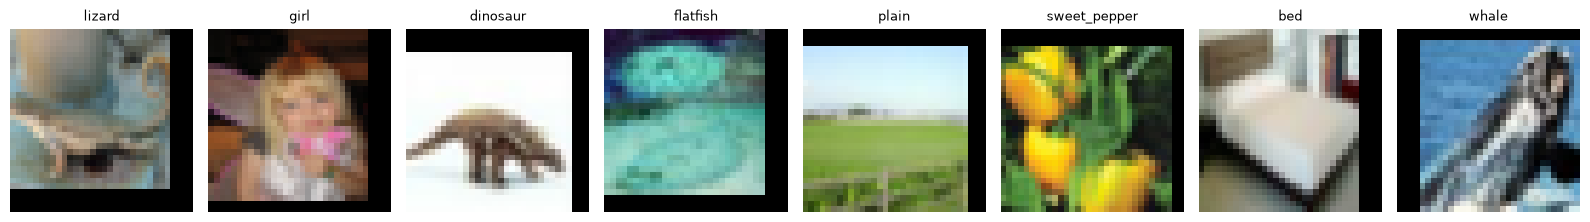

In [4]:
names = ds["train"].features["fine_label"].names

fig, axs = plt.subplots(1, 8, figsize=(16, 2.5))
for ax, i in zip(axs, np.random.choice(len(X), 8, replace=False)):
    ax.imshow((X[i].permute(1, 2, 0) * 0.5 + 0.5).clamp(0, 1))   # [-1, 1] -> [0, 1], [C, H, W] -> [H, W, C]
    ax.set_title(names[y[i]], fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

## Preparing Input for the Encoder

### Cut into Patches

#### Manual

We reshape the image $x \in \mathbb{R}^{H\times W \times C}$ into a sequence of flattened 2D patches $x_p \in \mathbb{R}^{N\times(P^2\cdot C)}$

* B - batch size, `X` is a single batch of 256 images from `train_loader`
* C - number of channels, we use 3: R, G, B
* H, W - height and width
* P - patch size, width of square patch
* D - embedding dimension, vector length on which we project each patch
* N - it's our `seq_len` so the count of patches per image. Since we're using transformer we are modifying the image into a sequence of those patches

* `X.unfold(dim, size, step)` - since our patches are squares we cut our X into `P` size segments on every `P` step, firstly on `dim=2` (H) then on `dim=3` (W), which together gives `P×P` squares. New dimensions are added at the end, that's why our new shape becomes `[256, 3, 8, 8, 4, 4]`, where `[8, 8]` corresponds to all patches and `[4, 4]` to all pixels in each patch. For example `[:10,:,0,-1,2,3]` will take from first 10 images all 3 channels and for each image we take patch from 1st row `0` of last column `-1`, and for each selected patch we take pixel from 3rd row `2` and 4th column `3`

##### Patch Params

In [5]:
B, C, H, W = X.shape          # [256, 3, 32, 32]
P, D = patch_size, embed_dim  # 4, 256
N = (H // P) * (W // P)       # 64

In [6]:
X.shape

torch.Size([256, 3, 32, 32])

In [7]:
patches = X.unfold(2, P, P).unfold(3, P, P) # [B, C, H/P, W/P, P, P]
patches.shape

torch.Size([256, 3, 8, 8, 4, 4])

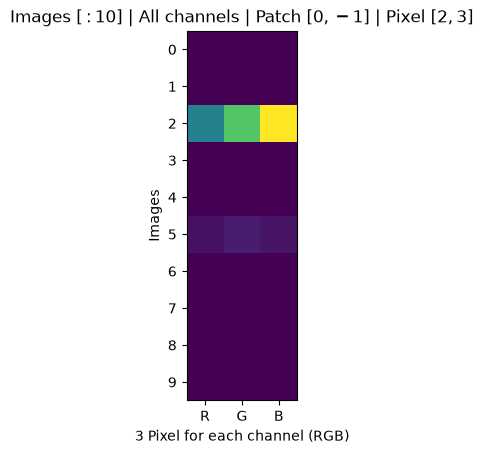

In [8]:
plt.imshow(patches[:10,:,0,-1,2,3], aspect='equal')
plt.ylabel('Images')
plt.xlabel('3 Pixel for each channel (RGB)')
plt.xticks([0, 1, 2], ['R', 'G', 'B'])
plt.yticks(np.arange(10))
plt.title('Images $[:10]$ | All channels | Patch $[0,-1]$ | Pixel $[2,3]$')
plt.show()

##### Patches Permute

We want to keep shapes clean and keep that in that order:

`[B, H/P, W/P, C, P, P]`

so we have `[Batch, Patches in Height, Patches in Width, Channels, Pixels in Patch Height, Pixels in Patch Width]` so that upcoming reshape can flatten [H/P, W/P] into N patches and [C, P, P] into one vector per patch.

In [9]:
patches = patches.permute(0, 2, 3, 1, 4, 5) # [B, H/P, W/P, C, P, P]
patches.shape

torch.Size([256, 8, 8, 3, 4, 4])

##### Patches Reshape

Again, we are working with transformer which accepts sequential data. All we want is to make a sequence out of image. Reshape takes us there. For each image in batch `B` we create `N` patches which is `(H//P) * (W//P)` so number of patches in each image. Last dimension is blended from last 3 dimensions so content of a single patch `C * P * P`. Reshape function takes dimensions in order, that's why we've done permute at the beginning. Now, we "blend" patches dimensions together, and channel and pixel dimensions separately.

In [10]:
patches = patches.reshape(B, N, C * P * P) # [B, (H//P) * (W//P) = N, P * P * C]
patches.shape

torch.Size([256, 64, 48])

##### Linear Projection

Important thing is that final shape of patches is `[Batch size, Count of Patches, Count of Pixel values per Patch]`. We could assume that since transformer is sequence based we should have final dimension of `[Batch size, Count of Patches * Count of Pixel values per Patch]` since sequence is 1-dimensional, so each image in batch would have 1 array of pixels. However, transformer takes shape of `[B, seq_len, embed_dim]` so each token in sequence has its own embedding, i.e. vector of multiple values, which serves as an encoded representation of that token. Here we do exactly the same, we just don't have `embed_dim` at the end just yet. Linear projection does exactly that, it changes `[B, N, P * P * C]` into `[B, N, D]` where `D` is embedding dimension.

In [11]:
proj = nn.Linear(C * P * P, D) # [B, N, D]
patch_emb = proj(patches)
patch_emb.shape

torch.Size([256, 64, 256])

In [12]:
B, N, D

(256, 64, 256)

##### Test

In [13]:
patches_man = X.unfold(2, P, P).unfold(3, P, P)        # [B, C, H/P, W/P, P, P]
patches_man = patches_man.permute(0, 2, 3, 1, 4, 5)        # [B, H/P, W/P, C, P, P]
patches_man = patches_man.reshape(B, N, C * P * P)         # [B, N, P²·C]
proj = nn.Linear(C * P * P, D)
patches_man = proj(patches_man)
patches_man.shape

torch.Size([256, 64, 256])

#### Torch

##### Patch Params

First, let's setup our parameters

In [14]:
B, C, H, W = X.shape
P, D = patch_size, embed_dim
n_patches = (H // P) * (W // P)

##### Conv2d

`nn.Conv2d` expects shape of `[B, C, H, W]` and arguments `in`, `out`, `kernel_size`, `stride`. `kernel_size` is `P` and we want non-overlapping square patches so `stride` is also `P`. `in` and `out` refer only to `dim=1` so `C`, i.e. `in = 3` which is RGB and `out` is our `embed_dim=256`. Eventually from shape `[256, 3, 32, 32]` or `[B, C, H, W]` we get `[B, D, H//P, W//P]`.

In [15]:
X.shape

torch.Size([256, 3, 32, 32])

In [16]:
conv = nn.Conv2d(C, D, kernel_size=P, stride=P)(X)
conv.shape

torch.Size([256, 256, 8, 8])

Here, convolution does patching and linear projection in one step, so we get `embed_dim` directly without a separate `nn.Linear`.

##### Flatten

Then we `flatten(start_dim=2)`, which merges all dimensions starting from `start_dim` into one. Eventually we just turn the grid of patches `[B, D, H//P, W//P]` into a sequence `[B, D, N]`, where `N = (H//P) * (W//P)`.

In [17]:
patch_emb = conv.flatten(2)
patch_emb.shape

torch.Size([256, 256, 64])

##### Transpose

As we explained in the Manual implementation, the transformer expects `[B, seq_len, D]`, so we need to transpose the 2 last dimensions.

In [18]:
patch_emb = patch_emb.transpose(1,2)
X.shape, patch_emb.shape

(torch.Size([256, 3, 32, 32]), torch.Size([256, 64, 256]))

And we get exactly the same output shape as in the Manual implementation.

##### Test

In [19]:
conv = nn.Conv2d(C, D, kernel_size=P, stride=P)
# Copy weights from nn.Linear from manual implementation to nn.Conv2d so we get same layers
with torch.no_grad():
  conv.weight.copy_(proj.weight.reshape(D, C, P, P)) # # [256, 48] -> [256, 3, 4, 4]
  conv.bias.copy_(proj.bias)
patches_pt = conv(X).flatten(2).transpose(1,2)
X.shape, conv(X).shape, patches_pt.shape

(torch.Size([256, 3, 32, 32]),
 torch.Size([256, 256, 8, 8]),
 torch.Size([256, 64, 256]))

Now, lets see if manual and conv implementation are the same:

In [20]:
patches_pt.shape, patches_man.shape

(torch.Size([256, 64, 256]), torch.Size([256, 64, 256]))

In [21]:
torch.allclose(patches_pt, patches_man)

False

But...

In [22]:
torch.allclose(patches_pt, patches_man, atol=1e-5)

True

As a default `torch.allclose` has `atol=1e-8` (absolute tolerance) which is very strict and returns False. `nn.Linear()` and `nn.Conv2d()` use different algorithms in different addition order, which in `float32` returns difference of `~1e-6` which is noise. By increasing `atol=1e-5` we get True.

In [23]:
(patches_man - patches_pt).abs().max()

tensor(7.1526e-07, grad_fn=<MaxBackward1>)

As we can see highest difference between two outputs is of size `1e-6`.

#### Official

It's very simple preprocessing. Each patch (3 channels × `P` × `P`) is projected onto 256 `embed_dim`, height and width of each image are divided into patches of size `P=4`, "blend" height and width dimensions into 1 array, finally transpose to get clean `[B, N, D]`, where `N` corresponds to `seq_len` in traditional transformer.

In [24]:
conv = nn.Conv2d(C, D, kernel_size=P, stride=P)
patch_emb = conv(X).flatten(2).transpose(1,2)
X.shape, conv(X).shape, patch_emb.shape

(torch.Size([256, 3, 32, 32]),
 torch.Size([256, 256, 8, 8]),
 torch.Size([256, 64, 256]))

#### Visualization

On left we have a single image `[3, 32, 32]` and on right its patch embedding `[64, 256]`. Of course it's a single image, that's why we index one `row` from the batch of 256.

Text(0.5, 1.0, 'Patch Embedding: $(64, 256)$')

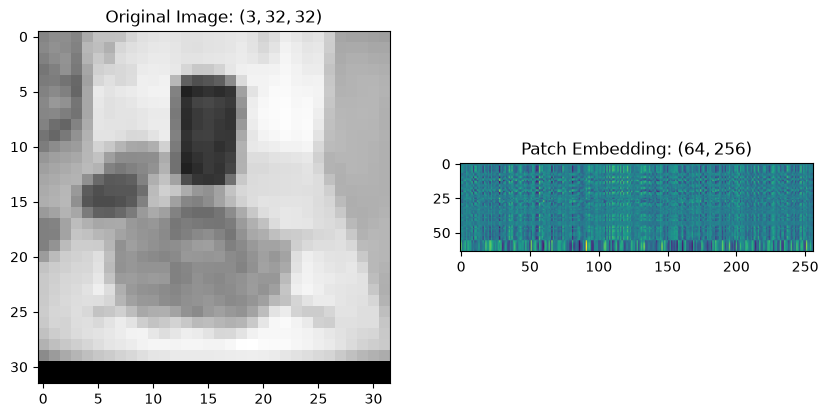

In [25]:
fig, ax = plt.subplots(1,2,figsize=(10,5))

row = np.random.randint(X.shape[0])

ax[0].imshow(X[row][0], cmap = 'grey')
ax[0].set_title(f'Original Image: ${X.shape[1], X.shape[2], X.shape[3]}$')
ax[1].imshow(patch_emb[row].detach().numpy())
ax[1].set_title(f'Patch Embedding: ${patch_emb.shape[1], patch_emb.shape[2]}$')

### Token Embedding - [CLS]

#### Manual

* First we prepend a learnable [CLS] token to the patch sequence: `[B, N, D]` $\rightarrow$ `[B, N+1, D]`, i.e. `[B, 64, D]` $\rightarrow$ `[B, 65, D]`. Through attention it gathers information from all patches.
* Each image gets 1 additional token (a vector of 256 values) which serves as a global representation of the whole image.
* At the encoder output we take only the `[CLS]` token as the image representation and feed it to the classification head.
* Why `z0`? We follow the paper's notation. $z_\ell$ denotes the sequence of tokens at layer $\ell$ of the Transformer encoder, so $z_0$ is the input to the encoder (layer 0), and $z_L$ is the output of the last layer $L$. For now our $z_0$ is:

$$z_0 = [x_{class};\ x_p^1E;\ x_p^2E;\ \dots;\ x_p^NE]$$

  where $x_{class}$ is the [CLS] token and $x_p^iE$ is the $i$-th patch after linear projection $E$. For classification the paper uses $z_L^0$, i.e. the [CLS] token (index `0`) at the output of the last layer, normalized as $y = \text{LN}(z_L^0)$ (Eq. 4).

In [26]:
cls = np.zeros((B, 1, D))                                          # [256, 1, 256]
z0 = np.concatenate([cls, patch_emb.detach().numpy()], axis=1)     # [256, 65, 256]
cls.shape, z0.shape

((256, 1, 256), (256, 65, 256))

#### Torch / Official

In `.expand()` `-1` means leave without changes.

In [27]:
cls_token = nn.Parameter(torch.zeros(1, 1, D))   # [1, 1, 256]
cls = cls_token.expand(B, -1, -1)                # [256, 1, 256]
z0 = torch.cat([cls, patch_emb], dim=1)          # [256, 65, 256]
cls.shape, z0.shape

(torch.Size([256, 1, 256]), torch.Size([256, 65, 256]))

#### Visualization

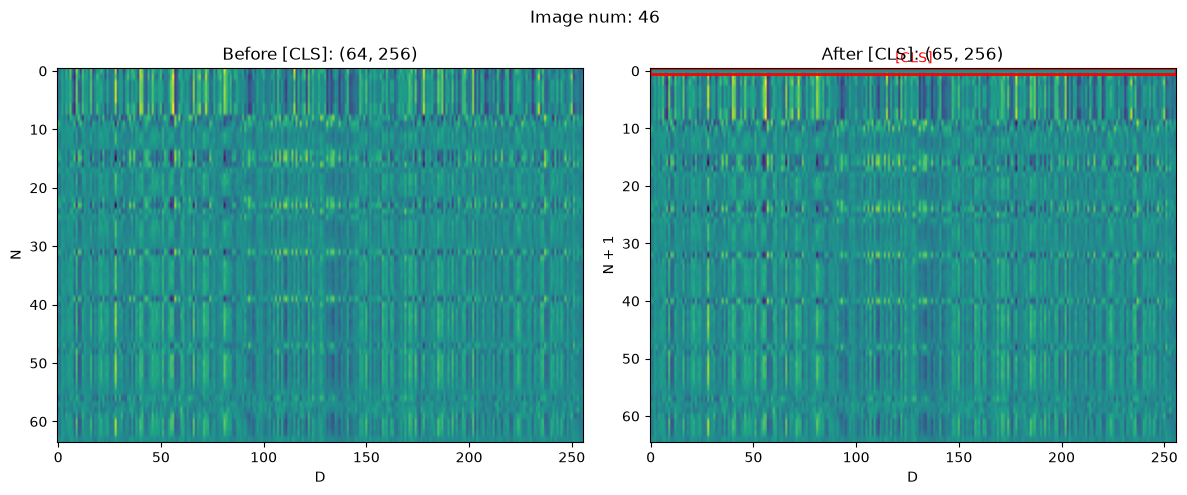

In [28]:
from matplotlib.patches import Rectangle

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
row = np.random.randint(B)

ax[0].imshow(patch_emb[row].detach().numpy(), aspect='auto')
ax[0].set_title(f'Before [CLS]: {tuple(patch_emb[row].shape)}')
ax[0].set_xlabel('D'); ax[0].set_ylabel('N')

ax[1].imshow(z0[row].detach().numpy(), aspect='auto')
ax[1].set_title(f'After [CLS]: {tuple(z0[row].shape)}')
ax[1].set_xlabel('D'); ax[1].set_ylabel('N + 1')
ax[1].add_patch(Rectangle((-0.5, -0.5), D, 1, fill=False, edgecolor='red', linewidth=2))
ax[1].text(D / 2, -1.5, '[CLS]', color='red', ha='center')

plt.suptitle(f'Image num: {row}')
plt.tight_layout()
plt.show()

We've added [CLS] token as encoder of each image.

### Position Embedding

#### Manual

We're going to initialize positional embeddings from a normal distribution, even though in the official code they are initialized with `trunc_normal_`. Let's remember that our images are already patched, i.e. we don't have a 2D image but a 1D sequence of patches. `[B, N+1, D]` means that we have `B=256` images and `N+1=65` tokens in a sequence put one after another: the [CLS] token at the beginning followed by `N=64` patches. In `N+1` we just have the index of each token, but `D=256` is what actually makes a patch a patch, i.e. its embedding.

Now, after bringing that back, we can add positional embeddings. We generate 1 matrix of shape `[1, N+1, D]` $\rightarrow$ `[1, 65, 256]`, and later on we broadcast the same matrix across every image. We do that so the model knows which patch has which index. To do so we add random values from a normal distribution to each token, and these values are trained later on. Of course this order is not for us; if it were, we would've just used `arange()` and indexed each patch. Positional embeddings are for the model, so that while processing it has some abstraction of the order of patches. We can see them as a positional tag for each token, the [CLS] token included.

After adding positional embeddings our $z_0$ is complete, exactly as in the paper (Eq. 1):

$$z_0 = [x_{class};\ x_p^1E;\ x_p^2E;\ \dots;\ x_p^NE] + E_{pos}$$

where $E_{pos} \in \mathbb{R}^{(N+1) \times D}$ are the positional embeddings, i.e. our `pos_embed` of shape `[1, N+1, D]`.

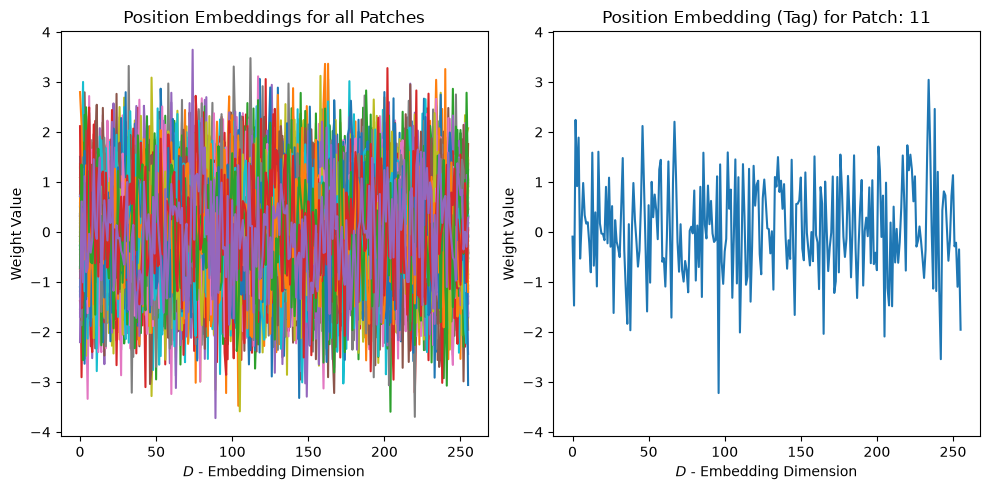

In [29]:
pos_embed = np.random.randn(1, N+1, D)
rand_row  = np.random.randint(N+1)

fig, axs = plt.subplots(1,2,figsize=(10,5))

axs[0].plot(pos_embed.squeeze().T)
axs[0].set_title('Position Embeddings for all Patches')
axs[0].set_xlabel('$D$ - Embedding Dimension')
axs[0].set_ylabel('Weight Value')

axs[1].plot(pos_embed.squeeze()[rand_row])
axs[1].set_title(f'Position Embedding (Tag) for Patch: {rand_row}')
axs[1].set_ylim(axs[0].get_ylim())
axs[1].set_ylabel('Weight Value')
axs[1].set_xlabel('$D$ - Embedding Dimension')

plt.tight_layout()
plt.show()

As we can see, each patch - or rather each position - gets its own embedding, i.e. a tag. What is important is that the token at a given position (e.g. `rand_row` on the right plot) gets the same position embedding in every image in the batch. That's why we call it a position embedding, not a token embedding: it encodes the position, not the content. Note that row `0` is the [CLS] token, so rows `1` to `64` correspond to the actual patches.

At the end we broadcast the positional embeddings to all images. Let's keep in mind that the positional embeddings tensor has shape `[1, N+1, D]` and not `[B=256, N+1, D]`. That means when we add it to our sequence of tokens `z0` (the [CLS] token + embedded patches), PyTorch broadcasts the same positional embeddings across every image in the batch: `[B, N+1, D] + [1, N+1, D]` $\rightarrow$ `[B, N+1, D]`.

In [30]:
z0_manual = z0 + torch.tensor(pos_embed, dtype=torch.float32)   # numpy is float64 -> keep float32
print('z0 before position embedding:', z0.shape, z0.dtype)
print('z0 after position embedding: ', z0_manual.shape, z0_manual.dtype)

z0 before position embedding: torch.Size([256, 65, 256]) torch.float32
z0 after position embedding:  torch.Size([256, 65, 256]) torch.float32


#### Torch / Official

Here we create a matrix of zeros with `torch.zeros(1, N+1, D)` and wrap it in `nn.Parameter()`, which makes it a learnable parameter of the model, so its values are updated during training. Then we initialize it in place with `nn.init.trunc_normal_` with `std=0.02`, as in the official implementation. The rest is the same as in Manual.

In [31]:
pos_embed = nn.Parameter(torch.zeros(1, N+1, D)) # [1, 65, 256] - one vector for each token position ([CLS] + 64 patches)
nn.init.trunc_normal_(pos_embed, std=0.02)        # official weight initialization
print('z0 before position embedding:', z0.shape)
z0 = z0 + pos_embed
print('z0 after position embedding: ', z0.shape)

z0 before position embedding: torch.Size([256, 65, 256])
z0 after position embedding:  torch.Size([256, 65, 256])


# Transformer

Breakdown of the transformer can be found here: https://github.com/AdrianKazi/GPT_Deconstruction

## MLP

In [32]:
class Block(nn.Module):
    def __init__(self, D, n_heads, mlp_dim, dropout):
        super().__init__()
        self.ln1 = nn.LayerNorm(D, eps=1e-6)
        self.attn = nn.MultiheadAttention(D, n_heads, dropout=0.0, batch_first=True)   # official: attention_dropout_rate = 0
        self.drop = nn.Dropout(dropout)
        self.ln2 = nn.LayerNorm(D, eps=1e-6)
        self.mlp = nn.Sequential(
            nn.Linear(D, mlp_dim),      # [B, N+1, D] -> [B, N+1, mlp_dim]
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(mlp_dim, D),      # [B, N+1, mlp_dim] -> [B, N+1, D]
            nn.Dropout(dropout),
        )

    def forward(self, z):                                               # z: [B, N+1, D]
        h = self.ln1(z)
        z = z + self.drop(self.attn(h, h, h, need_weights=False)[0])    # Eq. 2: z' = MSA(LN(z)) + z
        z = z + self.mlp(self.ln2(z))                                   # Eq. 3: z = MLP(LN(z')) + z'
        return z                                                        # [B, N+1, D]

In [33]:
encoder = nn.Sequential(*[Block(D, n_heads, mlp_dim, dropout) for _ in range(n_blocks)])
ln_final = nn.LayerNorm(D, eps=1e-6)
head = nn.Linear(D, n_classes)

zL = encoder(z0[:8])              # [8, 65, 256]
y_cls = ln_final(zL[:, 0])        # Eq. 4: only CLS -> [8, 256]
logits = head(y_cls)              # [8, 100]
zL.shape, y_cls.shape, logits.shape

(torch.Size([8, 65, 256]), torch.Size([8, 256]), torch.Size([8, 100]))

# ViT

In [34]:
class ViT(nn.Module):
    def __init__(self, img_size=img_size, patch_size=patch_size, in_ch=3, D=embed_dim, n_heads=n_heads,
                 n_blocks=n_blocks, mlp_dim=mlp_dim, n_classes=n_classes, dropout=dropout, representation_size=None):
        super().__init__()
        N = (img_size // patch_size) ** 2
        self.patch_embed = nn.Conv2d(in_ch, D, kernel_size=patch_size, stride=patch_size)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, D))
        self.pos_embed = nn.Parameter(torch.zeros(1, N + 1, D))
        self.dropout = nn.Dropout(dropout)
        self.encoder = nn.Sequential(*[Block(D, n_heads, mlp_dim, dropout) for _ in range(n_blocks)])
        self.ln = nn.LayerNorm(D, eps=1e-6)
        # Pre-training: MLP head with one hidden layer (tanh); fine-tuning: single linear layer
        self.pre_logits = nn.Sequential(nn.Linear(D, representation_size), nn.Tanh()) if representation_size else nn.Identity()
        self.head = nn.Linear(representation_size or D, n_classes)
        self._init_weights(in_ch * patch_size ** 2)

    def _init_weights(self, patch_fan_in):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                nn.init.normal_(m.bias, std=1e-6)
        nn.init.trunc_normal_(self.patch_embed.weight, std=math.sqrt(1 / patch_fan_in))   # lecun_normal
        nn.init.zeros_(self.patch_embed.bias)
        nn.init.normal_(self.pos_embed, std=0.02)
        nn.init.zeros_(self.head.weight)
        nn.init.zeros_(self.head.bias)

    def forward(self, x):                                      # [B, C, H, W]
        x = self.patch_embed(x).flatten(2).transpose(1, 2)     # [B, N, D]
        cls = self.cls_token.expand(x.shape[0], -1, -1)        # [B, 1, D]
        z = torch.cat([cls, x], dim=1) + self.pos_embed        # Eq. 1: z0 [B, N+1, D]
        z = self.encoder(self.dropout(z))                      # Eq. 2, 3: [B, N+1, D]
        y = self.ln(z[:, 0])                                   # Eq. 4: y = LN(z_L^0) [B, D]
        return self.head(self.pre_logits(y))                   # [B, n_classes]

## Train

In [ ]:
model = ViT().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=base_lr, betas=betas, weight_decay=weight_decay)
loss_fn = nn.CrossEntropyLoss()

# Linear warmup, then cosine decay to 0 (per step)
total_steps = epochs * len(train_loader)
def lr_lambda(step):
    if step < warmup_steps:
        return step / warmup_steps
    return 0.5 * (1 + math.cos(math.pi * (step - warmup_steps) / (total_steps - warmup_steps)))
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

@torch.no_grad()
def test_acc(model):
    model.eval()
    correct = n = 0
    for xb, yb in test_loader:
        correct += (model(xb.to(device)).argmax(1).cpu() == yb).sum().item()
        n += len(yb)
    model.train()
    return correct / n

use_amp = device.type == 'cuda'
print(f'params: {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M | steps: {total_steps}')

for epoch in range(epochs):
    model.train()
    t0, loss_sum, correct, seen = time.time(), 0.0, 0, 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, dtype=torch.bfloat16, enabled=use_amp):
            logits = model(xb)
            loss = loss_fn(logits, yb)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
        optimizer.step()
        scheduler.step()

        loss_sum += loss.item() * len(yb)
        correct += (logits.argmax(1) == yb).sum().item()
        seen += len(yb)
    log = (f'epoch {epoch:3d} | loss {loss_sum / seen:.3f} | train acc {correct / seen:.3f} | '
           f'lr {scheduler.get_last_lr()[0]:.2e} | {time.time() - t0:.0f}s')
    if epoch % 10 == 0 or epoch == epochs - 1:
        log += f' | test acc {test_acc(model):.3f}'
    print(log)

# Eval

In [35]:
train_eval_loader = DataLoader(ds["train"], batch_size=1000, num_workers=num_workers,
                               collate_fn=partial(collate, t=tf))

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    top1 = top5 = n = 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        top1 += (logits.argmax(1) == yb).sum().item()
        top5 += (logits.topk(5, dim=1).indices == yb[:, None]).any(1).sum().item()
        n += len(yb)
    return top1 / n, top5 / n

print('train top1/top5:', evaluate(model, train_eval_loader))
print('test  top1/top5:', evaluate(model, test_loader))

train top1/top5: (0.99974, 1.0)


test  top1/top5: (0.5774, 0.813)


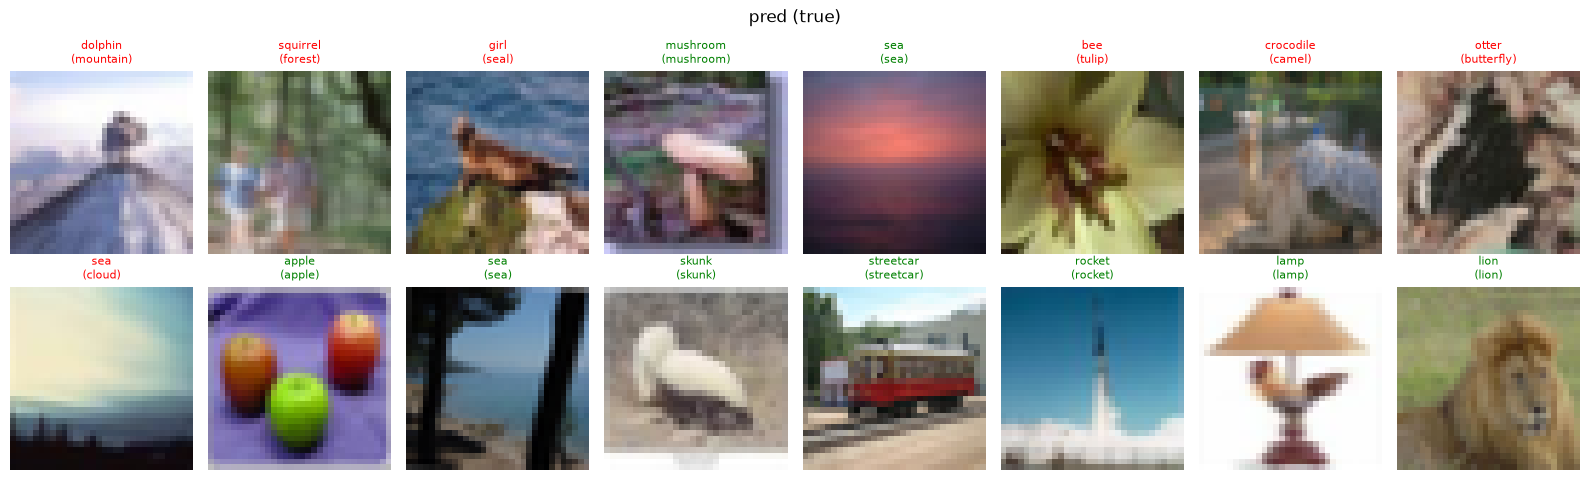

In [36]:
xb, yb = next(iter(test_loader))
model.eval()
with torch.no_grad():
    pred = model(xb[:16].to(device)).argmax(1).cpu()

fig, axs = plt.subplots(2, 8, figsize=(16, 5))
for i, ax in enumerate(axs.flat):
    ax.imshow((xb[i].permute(1, 2, 0) * 0.5 + 0.5).clamp(0, 1))   # undo normalization for display
    ok = pred[i] == yb[i]
    ax.set_title(f'{names[pred[i]]}\n({names[yb[i]]})', color='green' if ok else 'red', fontsize=8)
    ax.axis('off')
plt.suptitle('pred (true)')
plt.tight_layout()
plt.show()

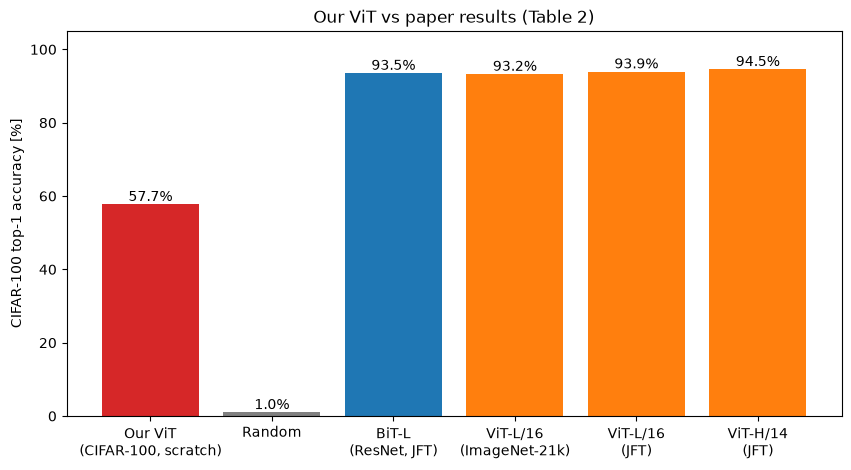

In [37]:
top1, _ = evaluate(model, test_loader)
results = {
    'Our ViT\n(CIFAR-100, scratch)': top1 * 100,
    'Random': 1.0,
    'BiT-L\n(ResNet, JFT)': 93.51,
    'ViT-L/16\n(ImageNet-21k)': 93.25,
    'ViT-L/16\n(JFT)': 93.90,
    'ViT-H/14\n(JFT)': 94.55,
}
plt.figure(figsize=(10, 5))
bars = plt.bar(results.keys(), results.values(), color=['tab:red', 'grey', 'tab:blue', 'tab:orange', 'tab:orange', 'tab:orange'])
plt.bar_label(bars, fmt='%.1f%%')
plt.ylabel('CIFAR-100 top-1 accuracy [%]')
plt.title('Our ViT vs paper results (Table 2)')
plt.ylim(0, 105)
plt.show()

# Save Model

In [ ]:
save_dir = '../checkpoints/vit_cifar100'
os.makedirs(save_dir, exist_ok=True)

config = dict(img_size=img_size, patch_size=patch_size, in_ch=3, D=embed_dim,
              n_heads=n_heads, n_blocks=n_blocks, mlp_dim=mlp_dim,
              n_classes=n_classes, dropout=dropout)
train_config = dict(batch_size=batch_size, epochs=epochs, base_lr=base_lr, weight_decay=weight_decay,
                    warmup_steps=warmup_steps, grad_clip=grad_clip, betas=betas)

test_top1, test_top5 = evaluate(model, test_loader)

torch.save({
    'model': model.state_dict(),
    'optimizer': optimizer.state_dict(),
    'config': config,
}, f'{save_dir}/vit.pt')

with open(f'{save_dir}/results.json', 'w') as f:
    json.dump({'config': config, 'train_config': train_config,
               'test_top1': test_top1, 'test_top5': test_top5}, f, indent=2)

print('saved to', save_dir, '| test top1:', test_top1)

# Load Model

In [38]:
ckpt = torch.load('../checkpoints/vit_cifar100/vit.pt', map_location=device, weights_only=True)
model = ViT(**ckpt['config']).to(device)
model.load_state_dict(ckpt['model'])
model.eval()

names = ds["test"].features["fine_label"].names
print('loaded, test top1/top5:', evaluate(model, test_loader))

loaded, test top1/top5: (0.5774, 0.813)


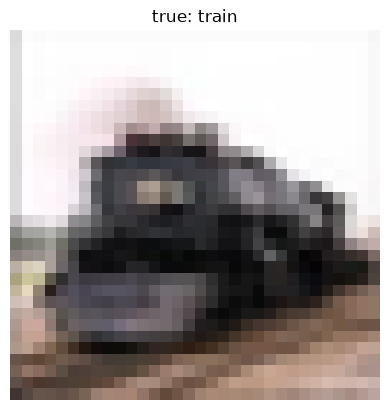

train           0.997
streetcar       0.002
tank            0.001
oak_tree        0.000
house           0.000


In [39]:
@torch.no_grad()
def predict(img, k=5):
    """img: PIL image (any size) -> top-k (class, prob)"""
    model.eval()
    x = tf(img.convert('RGB').resize((img_size, img_size))).unsqueeze(0).to(device)   # [1, 3, 32, 32]
    probs = model(x).softmax(1)[0]
    p, idx = probs.topk(k)
    return [(names[i], round(v.item(), 3)) for v, i in zip(p, idx)]

i = np.random.randint(len(ds["test"]))
img = ds["test"][i]["img"]

plt.imshow(img)
plt.title(f'true: {names[ds["test"][i]["fine_label"]]}')
plt.axis('off')
plt.show()

for cls, p in predict(img):
    print(f'{cls:15s} {p:.3f}')

# Next: Fine-tuning

The paper never trains ViT from scratch on CIFAR-100: it pre-trains on ImageNet-21k / JFT-300M and fine-tunes. Fine-tuning of the official ViT-B/16 weights (ImageNet-21k), loaded 1:1 into this `ViT` implementation, lives in the package code, see `src/vit/finetune.py` and the README:

```bash
python -m vit.finetune
```